# **PROJECT PHASE IV**
**Rachel MacMillan // rem388** <br>
**Valentina Fernández // jvf48**

## **Research Question** <br>
**How do patterns of leisure activities, including television viewing, social media use, reading, and exercise, differ across age groups, and how are these differences associated with cognitive and mental health assessment outcomes?**

Research on prolonged passive media consumption (such as binge-watching or "doomscrolling") shows that these activities negatively affect cognitive function and mental-wellbeing. Alternatively, active leisure activities such as reading and exercise are frequently associated with positive cognitive and psychological outcomes. 

Determining how leisure activities affect cognitive function and mental-wellbeing typically requires controlled experimental studies, which are difficult to conduct and beyond the scope of this project. Instead, we will investigate how leisure activity patterns vary across age groups and whether those patterns are associated with differences in cognitive and mental health assessments. 

By combining datasets that measure leisure activities, demographic characteristics, and cognitive or mental health outcomes, we hope to identify meaningful relationships between lifestyle behaviors and well-being. In particular, we are interested in whether age groups characterized by greater participation in passive screen-based activities differ from groups that spend more time reading or exercising with respect to measures such as distractibility, forgetfulness, and overall mental health. While our analysis will not establish causation, it may reveal patterns that help motivate future research on how different forms of leisure activity relate to cognitive and psychological well-being during diffrent stages of life.

## **Datasets and Descriptions**

**[2025 American Time Use Survey: Activity Summary File](https://www.bls.gov/tus/data/datafiles-2025.htm):** <br>
The U.S. Census Bureau annually conducts the American Time Use Survey (ATUS), funded by the U.S. Bureau of Labor Statistics, which measures how Americans divide their time among daily activities. These activities are organized into major categories such as personal care, eating and drinking, household activities, work, education, leisure and sports, and communication, with each category further divided into more detailed subcategories. 

ATUS participants are randomly selected from a subset of households that have completed their eighth month of interviews for the U.S. Census Population Survey. Participants are then interviewed once to collect time-use data of their previous day. Demographic information such as age, sex, marital status, occupation, income, and education are also recorded for each participant. Survey respondents understand that no identifiable information will be shared and that their contributing time-use data can be used for public analysis. 

ATUS provides several microdatasets regarding information on the respondent, activity, and activity summary. We will use ATUS's [Activity Summary File](https://drive.google.com/drive/folders/1Etczii3Ya7hL1ITElyc8QnaYF7_iJU_3?usp=sharing) (the raw data), which includes demographic and time-use data for each of the 6,145 participants. Detailed descriptions of dataset variables are included in the data cleaning section below.


**[Cognitive Assessment Questionnaire Dataset](https://data.mendeley.com/datasets/m2b8563ks5/1):** <br>
The Cognitive Assessment Questionnaire was designed to collect information about the frequency of everyday cognitive failures related to memory, perception, and attention. This survey was conducted by Vijayalaxmi Deshmukh, published by the Mendeley Data repository, and does not include any information about possible funding. 

A total of 1,399 participants completed a 25-question online survey in which they reported how often they experienced specific cognitive lapses during the previous six months. Responses were recorded on a 5-point scale ranging from 0 (Never) to 4 (Very Often). 

The questionnaire items are grouped into three dimensions of cognitive failure: Distractibility, Forgetfulness, and False Triggering. The dataset includes both the original survey responses and a processed version that classifies participants' levels of cognitive failure within each dimension as Low, Medium, or High. Detailed descriptions of dataset variables are included in the data cleaning section below.

**[2025 Behavioral Risk Factor Surveillance System Survey Data](https://www.cdc.gov/brfss/annual_data/annual_2025.html):** <br>
The U.S. Center for Disease Control and Prevention funds and annually conducts the Behavioral Risk Factor Surveillance System (BRFSS) Survey, which interviews Americans on their health behaviors, including whether they exercise and how frequently they have bad mental health days. The BRFSS helps local governments monitor health disparities and address emerging public health situations. 

The total sample for the 2025 BRFSS is 356,158. We are interested in respondents' age, sleep duration, and frequency of bad mental health days. Detailed descriptions of dataset variables and data processing methods are included in the data cleaning section below. 

**[2022 Health and Retirement Study (HRS): Core Data, Version 2.0](https://hrs.isr.umich.edu/data-products):** <br>
The University of Michigan conducts the Health and Retirement Study (HRS), a longitudinal survey of approximately 20,000 people in the United States. Researchers evaluate participants' health, cognition, employment, finances, family structure, and lifestyle through multiple methods. The HRS began in 1992 and has continued across multiple survey waves, with its most recent wave conducted in 2024.

For this project, we use the 2022 Core HRS data (version 2.0), which contains 15,787 respondent records. We selected this wave because it is the most recent wave that has been fully released and processed, and it includes complete codebooks. Specifically, we use four respondent-level files:

- Leave-Behind Questionnaire (h22lb_r.csv & H22LB_R.txt): contains information about participants' leisure activities, including reading, educational or training activities, television viewing, computer use, exercise, and walking.
- Cognition (h22d_r.csv & H22D_R.txt): contains measures of cognitive performance, including immediate and delayed word-recall tasks, which we use as measures of memory.
- Physical Health (h22c_r.csv & H22C_R.txt): contains measures of sleep quality and daily sedentary behavior.
- Demographics (h22a_r.csv & H22A_R.txt): provides participant characteristics, such as age, that may be used for comparisons with other datasets.


## **Preregristration Statements**
**Hypothetis #1:** People who participate in more active leisure activities (exercise, reading, hobbies) will have higher cognitive scores compared to people who participate in passive leisure activities(watching TV). <br>
**Analysis #1:** We will run two multivariate linear regressions with inputs of age, exercise, reading, hobbies, watching TV, and gaming to predict cognitive outcomes for immediate_recall and delayed_recall. So, we will test whether B(active activity) > 0, meaning that more time spent in active activities predicts higher scores for immediate and delayed recall. 

**Hypothetis #2:** People who participate in more passive leisure activities(watching TV) will have poorer mental health outcomes compared to those who participate in more active leisure activities. <br>
**Analysis #2:** We will run a multivariable linear regression with inputs of age, exercise, reading, hobbies, and watching TV to predict the number of bad mental health days per unit time. We will test B(passive activity) > 0, meaning that more time spent on passive activities predicts more bad mental health days.

## **Imports**


In [2]:
!pip install pandas numpy duckdb 
!pip install matplotlib
%pip install statsmodels
%pip install scikit-learn
!pip install seaborn

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from scipy.stats import chi2_contingency
from scipy.stats import chi2 as chi2_distribution

import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


## **Importing Cleaned Datasets** 

All of our cleaned datasets are grouped by the following age groups: <br>
- 15 - 24
- 25 - 34
- 35 - 44
- 45 - 54
- 55 - 64
- 65+

Within each group, we calculate means or category percentages, depending on the dataset. Missing responses are excluded separately for each variable, and HRS activity codes outside 1–7 are treated as missing. 

- `num_participants`: total participants in the age group.
- `mean_age`: average recorded age.
- `n_` columns: valid-response counts used for each mean or set of percentages.

Results are save to `data_cleaned` folder.

### **Addressing Limitations**

We decided to group in this manner because shared age groups help compare patterns despite the Cognitive Assessment sample having a larger proportion of younger participants and HRS having older proportion of participants. They do not eliminate differences in representation. Summaries are unweighted, and HRS frequency-code averages cannot be compared directly with ATUS minutes.

#### **Datasets & Variables:** 

**American Time Use Survey (ATUS) Dataset (`atus`):**
 - `avg_sleeping`: average minutes spent sleeping per day for age group
 - `avg_tv`: the average minutes spent watching TV per day for age group
 - `avg_gaming`: the average minutes spent gaming per day for age group
 - `avg_computer`: the average minutes spent using the computer for leisureper day for age group
 - `avg_artsCrafts`: the average minutes spent doing arts and crafts per day for age group
 - `avg_reading`: the average minutes spent reading for leisure per day for age group
 - `avg_writing`: the average minutes spent writing for leisure per day for age group
 - `avg_exercising`: the average minutes spent exercising per day for age group

**Cognitive Assessment Questionnaire Dataset (`cognitive_data`):**
- `low_forgetfulness_percentage`: percentage of participants in age group evaluated as having low forgetfulness
- `medium_forgetfulness_percentage`: percentage of participants in age group evaluated as having medium forgetfulness
- `high_forgetfulness_percentage`: percentage of participants in age group evaluated as having high forgetfulness
- `low_distractibility_percentage`: percentage of participants in age group evaluated as having low distractibility
- `medium_distractibility_percentage`: percentage of participants in age group evaluated as having medium distractibility
- `high_distractibility_percentage`: percentage of participants in age group evaluated as having high distractibility
- `yes_false_triggering_percentage`: percentage of participants in age group who experienced false triggering
- `no_false_triggering_percentage`: percentage of participants in age group who did not experience false triggering

**Behavioral Risk Factor Surveillance System Dataset (`mental_health`):**
- `exercised_percentage`: percentage of participants in age group who exercised within the last 30 days
- `no_bad_mental_health_days_percentage`: percentage of participants in age group who had no bad mental health days within the last 30 days
- `half_bad_mental_health_days_percentage`: percentage of participants in age group who had 1-13 bad mental health days within the last 30 days
- `most_bad_mental_health_days_percentage`: percentage of participants in age group who had more than 14 bad mental health days within the last 30 days
  
**Health and Retirement Survey (HRS) Dataset (`hrs`):** <br>
- The HRS data measures the **frequency of participation** in different leisure activities using an ordinal scale: <br>
    - `1`: Respondant participated in activity **daily**
    - `2`: Respondant participated in activity **several times a week**
    - `3`: Respondant participated in activity **once a week**
    - `4`: Respondant participated in activity **several times a month**
    - `5`: Respondant participated in activity **at least once a month**
    - `6`: Respondant **has not participated** in activity **within the past month**
    - `7`: Respondant **never participated** in the activity

- Sleep frequency is measured by an ordinal scale: <br>
    - `1` : Most of the time
    - `2` : Sometimes
    - `3` : Rarely or never
- Recall varibles (`avg_immediate_recall` and `avg_delayed_recall`) are measured on a scale from 1-10, with 1 being only 1 word being recalled correctly, and 10 being all 10 word were recalled correctly. Higher recall scores correspond to better recall. <br>

**Variables:** <br>

- `avg_education_training`: average frequency of paricipants in age group who attended educational training
- `avg_reading`: average frequency of paricipants in age group who read
- `avg_watching_tv`: average frequency of paricipants in age group who watch TV
- `avg_word_games`: average frequency of paricipants in age group who play word games
- `avg_card_games_chess`: average frequency of paricipants in age group who play card games or chess
- `avg_writing`: average frequency of paricipants in age group who write
- `avg_computer_internet`: average frequency of paricipants in age group who use the computer for internet
- `avg_hobbies`: average frequency of paricipants in age group who participate in hobbies
- `avg_exercising`: average frequency of paricipants in age group who exercise
- `avg_walking`: average frequency of paricipants in age group who walk
- `avg_trouble_falling_asleep`: average frequency of paricipants in age group who have trouble falling asleep
- `avg_waking_at_night`: average frequency of paricipants in age group who experience waking at night
- `avg_waking_too_early`: average frequency of paricipants in age group who experience waking too early
- `avg_feeling_rested`: average frequency of paricipants in age group who feel rested
- `avg_immediate_recall`: average immediate-recall scores for participants in age group
- `avg_delayed_recall`: average delayed-recall scores for participants in age group



In [3]:
atus = pd.read_csv("data_cleaned/atus.csv")
print("American Time Use (ATUS) Data:")
display(atus)
print()

cognitive = pd.read_csv("data_cleaned/cognitive_data.csv")
print("Cognitive Data: ")
display(cognitive)
print()

mental_health = pd.read_csv("data_cleaned/mental_health.csv")
print("Mental Health Data:")
display(mental_health)
print()

hrs = pd.read_csv("data_cleaned/hrs.csv")
print("Health and Retirement Study Data:")
display(hrs)

American Time Use (ATUS) Data:


,age_group,num_participants,mean_age,avg_sleeping,n_sleeping,avg_tv,n_tv,avg_gaming,n_gaming,avg_computer,n_computer,avg_artsCrafts,n_artsCrafts,avg_reading,n_reading,avg_writing,n_writing,avg_exercising,n_exercising
0,15-24,440,19.94,610.01,440,115.74,440,54.35,440,19.20,440,3.72,440,10.71,440,0.30,440,0.14,440
1,25-34,777,29.94,548.45,777,122.82,777,33.75,777,14.19,777,1.49,777,11.95,777,0.22,777,0.14,777
2,35-44,972,39.36,535.86,972,117.10,972,18.23,972,7.39,972,1.42,972,13.39,972,0.14,972,0.10,972
3,45-54,848,49.61,532.98,848,152.54,848,10.98,848,12.02,848,1.64,848,13.88,848,0.15,848,0.07,848
4,55-64,979,59.77,530.26,979,194.79,979,10.48,979,8.40,979,2.22,979,16.80,979,0.54,979,0.17,979
5,65+,2130,73.44,536.60,2130,261.70,2130,16.94,2130,11.64,2130,4.16,2130,34.61,2130,0.50,2130,0.12,2130



Cognitive Data: 


,age_group,num_participants,mean_age,n_forgetfulness,low_forgetfulness_percentage,medium_forgetfulness_percentage,high_forgetfulness_percentage,n_distractibility,low_distractibility_percentage,medium_distractibility_percentage,high_distractibility_percentage,n_false_triggering,yes_false_triggering_percentage,no_false_triggering_percentage
0,15-24,388,20.99,388,88.92,7.73,3.35,388,32.99,31.44,35.57,388,52.58,47.42
1,25-34,541,29.42,541,91.50,6.28,2.22,541,33.27,34.57,32.16,541,48.24,51.76
2,35-44,419,39.12,419,89.50,7.16,3.34,419,37.71,31.50,30.79,419,50.60,49.40
3,45-54,41,45.80,41,87.80,9.76,2.44,41,29.27,36.59,34.15,41,48.78,51.22
4,55-64,9,58.11,9,77.78,22.22,0.00,9,55.56,0.00,44.44,9,55.56,44.44
5,65+,1,65.00,1,100.00,0.00,0.00,1,0.00,100.00,0.00,1,100.00,0.00



Mental Health Data:


,age_group,num_participants,mean_age,n_exercise,exercised_percentage,not_exercised_percentage,n_bad_mental_health_days,no_bad_mental_health_days_percentage,half_bad_mental_health_days_percentage,most_bad_mental_health_days_percentage
0,15-24,23238,21.03,23188,85.38,14.62,22857,39.45,40.43,20.12
1,25-34,37370,29.59,37320,82.91,17.09,36819,41.14,38.77,20.09
2,35-44,44929,39.56,44858,81.95,18.05,44234,46.95,33.87,19.18
3,45-54,47713,49.65,47600,78.40,21.60,46934,53.35,29.07,17.57
4,55-64,60683,59.72,60514,75.34,24.66,59688,60.72,24.24,15.04
5,65+,142225,73.83,141704,72.32,27.68,139142,73.20,17.81,8.99



Health and Retirement Study Data:


,age_group,num_participants,mean_age,avg_education_training,n_education_training,avg_reading,n_reading,avg_watching_tv,n_watching_tv,avg_word_games,...,avg_feeling_rested,n_feeling_rested,avg_immediate_recall,n_immediate_recall,avg_delayed_recall,n_delayed_recall,avg_sitting_hours,n_sitting_hours,avg_sitting_minutes,n_sitting_minutes
0,15-24,0,NaN,NaN,0,NaN,0,NaN,0,NaN,...,NaN,0,NaN,0,NaN,0,NaN,0,NaN,0
1,25-34,11,31.36,4.50,2,1.50,2,2.50,2,5.00,...,2.73,11,6.36,11,6.00,11,5.18,11,0.00,11
2,35-44,120,41.08,6.20,20,3.00,20,1.65,20,4.16,...,1.92,120,6.02,116,5.04,115,5.30,112,2.59,87
3,45-54,1494,51.63,6.06,289,3.39,289,1.70,287,4.62,...,1.89,1492,5.95,1436,4.85,1433,5.97,1462,1.47,1131
4,55-64,5187,59.94,6.28,1310,3.13,1313,1.46,1312,4.33,...,1.76,5173,5.74,4666,4.68,4652,5.83,4983,2.45,3298
5,65+,8975,75.26,6.49,2767,2.55,2769,1.35,2775,4.15,...,1.59,8913,5.05,7419,3.98,7364,5.52,8428,2.43,5053


We used consistent age categories across datasets to organize comparisons. Each dataset was analyzed separately using its original measurement scale: daily minutes for ATUS, activity-frequency percentages for HRS, and category percentages for BRFSS and cognitive assessment outcomes. We compared general patterns across age groups without treating these measures as equivalent. Analyses used available valid responses, with variable-specific sample sizes reported. HRS questionnaire ineligibility was distinguished from nonresponse, and findings were interpreted with attention to selection bias and sparse age groups.

## **Data Analysis**

### **Hypothesis #1: People who participate in more active leisure activities (exercise, reading, hobbies) will have higher cognitive scores compared to people who participate in passive leisure activities(watching TV).**

We will run this hypothesis on the HRS participant data, which includes participants aged 30 to 101 to examine whether participation in **exercise**, **reading**, **watching television**, and **hobbies** is assosicated with **delayed or immediate recall scores**. <br>
We will fit two multiple linear regressions: one for **immediate recall** and one for **delayed recall**. Both outcomes measure the number of words correctly recalled, from 0 to 10.

**Preparing the data.** We select respondents eligible for the Leave-Behind Questionnaire and include **age**, **exercise**, **reading**, **hobbies**, and **television viewing** as predictors. Each model (`immediate_model_data` and `delayed_model_data`) only uses respondents with valid values for all its required variables. We reverse the activity codes for readibility, so that higher values indicate more frequent participation:  
- `0`: Respondant has **never participated** in the activity
- `1`: Respondant has **not participated** in activity **within the past month**
- `2`: Respondant participated in activity **at least once a month**
- `3`: Respondant participated in activity **several times a month**
- `4`: Respondant participated in activity **once a week**
- `5`: Respondant participated in activity **several times a week**
- `6`: Respondant participated in activity **daily**

**Fitting the models.** Following the train/test approach discussed in class, we randomly divide each model’s available records into **70% training data and 30% test data**. We use the training data to fit an ordinary least-squares regression, which chooses coefficients that minimize the sum of squared residuals. We explicitly add an intercept using `sm.add_constant()`.
**Interpreting coefficients.** Each activity coefficient describes the expected difference in recall score associated with a one-step increase in participation frequency, **all else equal**. Positive coefficients for exercise, reading, or hobbies would be in the direction predicted by Hypothesis 1. A negative television coefficient would indicate that more frequent television viewing is associated with lower recall.

In [ ]:
h1_hrs_regression_data = pd.read_csv("data_cleaned/h1_regression_data.csv")

display(h1_hrs_regression_data)

predictors = [
    "age",
    "exercising_participation",
    "reading_participation",
    "hobbies_participation",
    "watching_tv_participation"
] 

immediate_model_data = pd.read_csv("data_cleaned/h1_hrs_immediate_model_data.csv") 
display(immediate_model_data)
delayed_model_data = pd.read_csv("data_cleaned/h1_hrs_delayed_model_data.csv")


h1_hrs_datasets = {"immediate_recall": immediate_model_data,
                    "delayed_recall": delayed_model_data}
models = {}
training_samples = {}
coefficient_tables = []
evaluation_rows = []

for outcome, model_data in h1_hrs_datasets.items():

    X = model_data[predictors]
    y = model_data[outcome]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.30, random_state = 42)

    # Add intercept
    X_train = sm.add_constant(X_train, has_constant = "add")
    X_test = sm.add_constant(X_test, has_constant = "add")

    model = sm.OLS(y_train, X_train).fit()

    models[outcome] = model
    training_samples[outcome] = model_data.loc[X_train.index]

    print(f"\nOutcome: {outcome}")
    print(f"Valid records: {len(model_data):,}")
    print(f"Training records: {len(X_train):,}")
    print(f"Test records: {len(X_test):,}")

    print(model.summary())

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    for sample, actual, predicted in [("Training", y_train, train_predictions),
                                      ("Test", y_test, test_predictions)]:
        evaluation_rows.append({"outcome": outcome,
                                "sample": sample,
                                "MAE": mean_absolute_error(actual, predicted),
                                "RMSE": np.sqrt(mean_squared_error(actual, predicted))})

    baseline_predictions = np.repeat(y_train.mean(), len(y_test))

    evaluation_rows.append({"outcome": outcome,
                            "sample": "Test: mean-only baseline",
                            "MAE": mean_absolute_error(y_test, baseline_predictions),
                            "RMSE": np.sqrt(mean_squared_error(y_test, baseline_predictions))})

    confidence_intervals = model.conf_int()

    coefficient_tables.append(pd.DataFrame({"outcome": outcome,
                                            "predictor": model.params.index,
                                            "coefficient": model.params.values,
                                            "ci_lower": confidence_intervals.iloc[:, 0].values,
                                            "ci_upper": confidence_intervals.iloc[:, 1].values,
                                            "p_value": model.pvalues.values}))

evaluation_results = pd.DataFrame(evaluation_rows)

regression_results = pd.concat(coefficient_tables, ignore_index = True)

display(evaluation_results.round(3))
display(regression_results.round(4))

,age,immediate_recall,delayed_recall,exercising_participation,reading_participation,hobbies_participation,watching_tv_participation
0,66,5.0,2.0,6.0,6.0,6.0,6.0
1,77,7.0,5.0,NaN,NaN,NaN,NaN
2,74,5.0,6.0,NaN,NaN,NaN,NaN
3,85,4.0,4.0,6.0,6.0,6.0,6.0
4,79,6.0,4.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
8633,72,3.0,0.0,NaN,NaN,NaN,NaN
8634,63,4.0,4.0,NaN,NaN,NaN,NaN
8635,65,6.0,3.0,NaN,NaN,NaN,NaN
8636,67,5.0,2.0,1.0,1.0,0.0,6.0


,age,exercising_participation,reading_participation,hobbies_participation,watching_tv_participation,immediate_recall
0,66,6.0,6.0,6.0,6.0,5.0
1,85,6.0,6.0,6.0,6.0,4.0
2,83,5.0,6.0,1.0,6.0,4.0
3,81,5.0,5.0,0.0,6.0,4.0
4,83,0.0,6.0,0.0,6.0,4.0
...,...,...,...,...,...,...
4095,65,1.0,1.0,0.0,5.0,5.0
4096,48,3.0,2.0,0.0,6.0,4.0
4097,72,4.0,4.0,0.0,6.0,3.0
4098,82,6.0,1.0,0.0,6.0,2.0



Outcome: immediate_recall
Valid records: 4,100
Training records: 2,870
Test records: 1,230
                            OLS Regression Results                            
Dep. Variable:       immediate_recall   R-squared:                       0.138
Model:                            OLS   Adj. R-squared:                  0.136
Method:                 Least Squares   F-statistic:                     91.44
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           1.65e-89
Time:                        17:49:26   Log-Likelihood:                -5233.6
No. Observations:                2870   AIC:                         1.048e+04
Df Residuals:                    2864   BIC:                         1.052e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
------------------------

,outcome,sample,MAE,RMSE
0,immediate_recall,Training,1.189,1.499
1,immediate_recall,Test,1.183,1.521
2,immediate_recall,Test: mean-only baseline,1.302,1.644
3,delayed_recall,Training,1.406,1.782
4,delayed_recall,Test,1.471,1.871
5,delayed_recall,Test: mean-only baseline,1.579,1.996


,outcome,predictor,coefficient,ci_lower,ci_upper,p_value
0,immediate_recall,const,8.1891,7.7262,8.6520,0.0000
1,immediate_recall,age,-0.0500,-0.0555,-0.0444,0.0000
2,immediate_recall,exercising_participation,0.0289,0.0032,0.0545,0.0274
3,immediate_recall,reading_participation,0.1363,0.1070,0.1657,0.0000
4,immediate_recall,hobbies_participation,0.0711,0.0420,0.1001,0.0000
5,immediate_recall,watching_tv_participation,-0.0276,-0.0777,0.0224,0.2795
6,delayed_recall,const,7.0238,6.4710,7.5766,0.0000
7,delayed_recall,age,-0.0501,-0.0568,-0.0434,0.0000
8,delayed_recall,exercising_participation,0.0488,0.0183,0.0793,0.0017
9,delayed_recall,reading_participation,0.1248,0.0899,0.1596,0.0000


**Immediate Recall Regression Interpretations** <br>
- **R-Squared = 0.138**: About 13.8% of the variation in immediate recall scores can be explained by age, exercise, reading, hobbies, and television viewing. 
- **Age = -0.05; p-value < 0.001**: Each additional year of age is associated with about 0.05 fewer words recalled immediately, holding all activities constant. There is very strong evidence that the relationship between age and immediate recall is not due to random chance.
- **Exercise = 0.0289; p-value = 0.027**: A one-category increase in exercise frequency is associated with about 0.03 additional words recalled immediately, holding age and other activities constant. There is some evidence of a positive relationship between exercise frequency and immediate recall, but it is not strong.
- **Reading = 0.1363; p-value < 0.001**: A one-category increase in reading frequency is associated with about 0.14 additional words recalled immediately, holding age and other activities constant. There is very strong evidence that the relationship between reading frequency and immediate recall is not due to random chance.
- **Hobbies = 0.0711; p-value < 0.001**: A one-category increase in hobby participation frequency is associated with about 0.07 additional words recalled immediately, holding age and other activities constant. There is very strong evidence that the relationship between hobby participation frequency and immediate recall is not due to random chance.
- **Watching TV = -0.0276; p-value = 0.026**: A one-category increase in hobby participation frequency is associated with about 0.03 fewer words recalled immediately, holding age and other activities constant. There is some evidence of a negative relationship between television watching frequency and immediate recall, but it is not strong.

**Delayed Recall Regression Interpretations** <br>
- **R-Squared = 0.122**: About 12.2% of the variation in delayed recall scores can be explained by age, exercise, reading, hobbies, and television viewing. 
- **Age = -0.05; p-value < 0.001**: Each additional year of age is associated with about 0.05 fewer words recalled after a delay, holding all activities constant. There is very strong evidence that the relationship between age and delayed recall is not due to random chance.
- **Exercise = 0.0488; p-value = 0.0017**: A one-category increase in exercise frequency is associated with about 0.05 additional words recalled after a delay, holding age and other activities constant. There is strong evidence of a positive relationship between exercise frequency and delayed recall.
- **Reading = 0.1248; p-value < 0.001**: A one-category increase in reading frequency is associated with about 0.13 additional words recalled after a delay, holding age and other activities constant. There is very strong evidence that the relationship between reading frequency and delayed recall is not due to random chance.
- **Hobbies = 0.1435; p-value < 0.001**: A one-category increase in hobby participation frequency is associated with about 0.13 additional words recalled after a delay, holding age and other activities constant. There is very strong evidence that the relationship between hobby participation frequency and delayed recall is not due to random chance.
- **Watching TV = -0.0268; p-value = 0.3808**: A one-category increase in hobby participation frequency is associated with about 0.03 fewer words recalled after a delay, holding age and other activities constant. There is very weak evidence of a negative relationship between television watching frequency and delayed recall; this could easily be random variation.

Reading and hobby participation showed the strongest statistical evidence of positive associations with both immediate and delayed recall. Exercise participation showed evidence of a positive association with delayed recall and weaker evidence for immediate recall. Television viewing showed negative coefficients in both models, but the p-values indicated insufficient evidence to conclude that television participation was associated with recall performance.

**Checking model fit.** We will now plot training residuals—observed scores minus predicted scores—against predicted scores. We look for residuals scattered around zero without clear curvature or a changing spread. We also inspect their distribution and the correlations among predictors to identify possible problems with model assumptions or overlapping information.

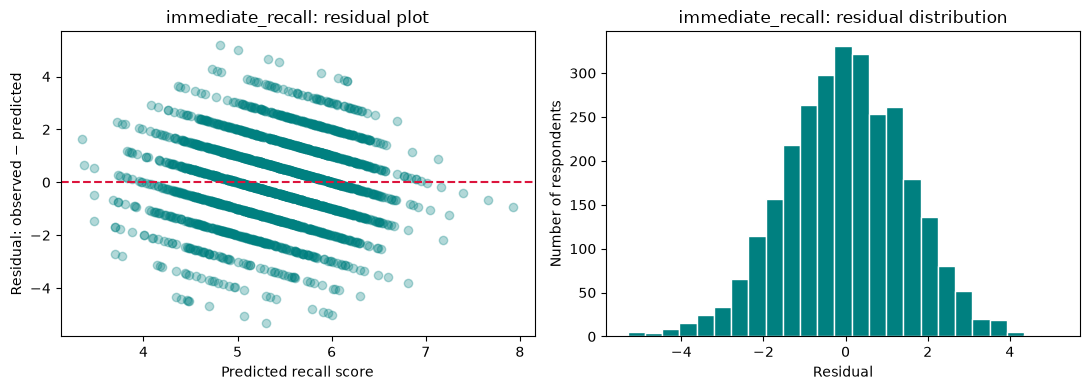

Predictor correlations: immediate_recall


,age,exercising_participation,reading_participation,hobbies_participation,watching_tv_participation
age,1.00,-0.06,0.18,-0.08,0.10
exercising_participation,-0.06,1.00,0.24,0.28,-0.00
reading_participation,0.18,0.24,1.00,0.22,0.08
hobbies_participation,-0.08,0.28,0.22,1.00,-0.04
watching_tv_participation,0.10,-0.00,0.08,-0.04,1.00


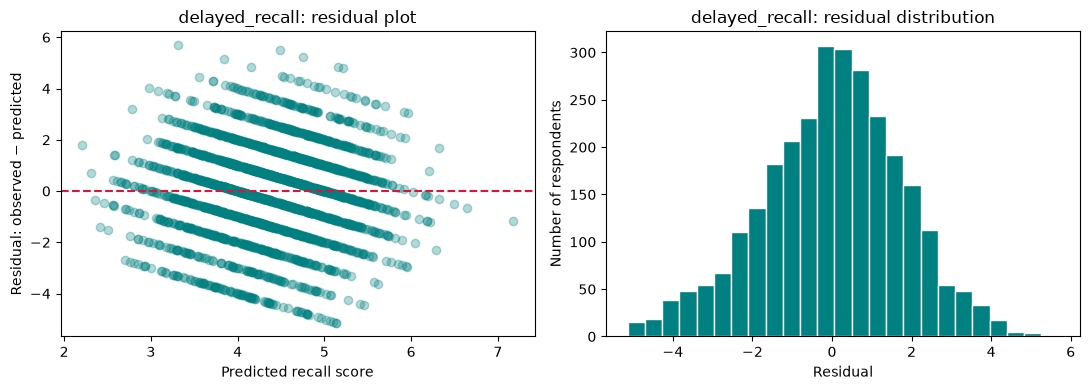

Predictor correlations: delayed_recall


,age,exercising_participation,reading_participation,hobbies_participation,watching_tv_participation
age,1.00,-0.07,0.20,-0.03,0.10
exercising_participation,-0.07,1.00,0.24,0.26,-0.01
reading_participation,0.20,0.24,1.00,0.20,0.08
hobbies_participation,-0.03,0.26,0.20,1.00,-0.02
watching_tv_participation,0.10,-0.01,0.08,-0.02,1.00


In [5]:
for outcome, model in models.items():

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].scatter(model.fittedvalues, model.resid, alpha = 0.3, color = "teal")
    
    axes[0].axhline(0, color = "crimson", linestyle="--")
    axes[0].set_xlabel("Predicted recall score")
    axes[0].set_ylabel("Residual: observed − predicted")
    axes[0].set_title(f"{outcome}: residual plot")

    axes[1].hist(model.resid, bins = 25, edgecolor = "white", color = "teal")

    axes[1].set_xlabel("Residual")
    axes[1].set_ylabel("Number of respondents")
    axes[1].set_title(f"{outcome}: residual distribution")

    plt.tight_layout()
    plt.show()

    print(f"Predictor correlations: {outcome}")
    display(training_samples[outcome][predictors].corr().round(2))

The residual plots for immediate and delayed recall show no major departures from linearity, and residuals are approximately centered around zero across the range of predicted values. The residual distribution was roughly bell-shaped, suggesting that the assumptions of linear regression were reasonably satisfied. Correlations among predictors were modest, indicating little evidence of problematic multicollinearity. Together, these diagnostics suggest that the regression coefficients provide a reasonable summary of the relationships between leisure activities and delayed recall. Reading, hobbies, and exercise were positively associated with delayed recall, while television viewing showed a small negative but statistically non-significant association.

#### **Evaluation of Significance**

**Assessing statistical evidence.** The regression tables report coefficient estimates, standard errors, two-sided p-values, and 95% confidence intervals. We apply a **Bonferroni correction** across the eight activity-coefficient tests: four activities in each of two models. This uses a significance threshold of **0.05 / 8 = 0.00625** to limit false positives across those tests. The reported 95% confidence intervals are individual intervals and are not adjusted by this correction.

In [6]:
activities = ["exercising", "reading", "hobbies", "watching_tv"]

activity_predictors = [f"{activity}_participation" for activity in activities]

activity_results = regression_results.loc[regression_results["predictor"].isin(activity_predictors)].copy()

number_of_tests = len(activity_results)
corrected_threshold = 0.05 / number_of_tests

activity_results["bonferroni_p_value"] = (activity_results["p_value"] * number_of_tests).clip(upper=1)

activity_results["significant_after_correction"] = (activity_results["p_value"] <= corrected_threshold)

print("Number of activity tests:", number_of_tests)
print("Corrected significance threshold:", corrected_threshold)

display(activity_results.round(4))

Number of activity tests: 8
Corrected significance threshold: 0.00625


,outcome,predictor,coefficient,ci_lower,ci_upper,p_value,bonferroni_p_value,significant_after_correction
2,immediate_recall,exercising_participation,0.0289,0.0032,0.0545,0.0274,0.2193,False
3,immediate_recall,reading_participation,0.1363,0.1070,0.1657,0.0000,0.0000,True
4,immediate_recall,hobbies_participation,0.0711,0.0420,0.1001,0.0000,0.0000,True
5,immediate_recall,watching_tv_participation,-0.0276,-0.0777,0.0224,0.2795,1.0000,False
8,delayed_recall,exercising_participation,0.0488,0.0183,0.0793,0.0017,0.0138,True
9,delayed_recall,reading_participation,0.1248,0.0899,0.1596,0.0000,0.0000,True
10,delayed_recall,hobbies_participation,0.1435,0.1090,0.1780,0.0000,0.0000,True
11,delayed_recall,watching_tv_participation,-0.0268,-0.0869,0.0332,0.3808,1.0000,False


After applying a Bonferroni correction for the eight activity-coefficient tests, reading and hobby participation remained significantly associated with both immediate and delayed recall. Exercise participation remained significantly associated with delayed recall but not immediate recall. Television viewing showed negative coefficients in both models, consistent with the hypothesized direction, but neither relationship was statistically significant. Overall, the results provide the strongest support for reading and hobbies as activities associated with higher cognitive performance.

**Limitations.** Treating activity codes as numeric assumes equal steps between frequency categories, although those categories are not equally spaced in time. The models estimate associations rather than causal effects and do not account for survey weights or the full HRS sampling design. Findings also depend on which eligible respondents provided complete responses. Gaming is omitted because the selected HRS variables do not match the ATUS gaming measure.

#### **Hypothesis #1 Conclusion**
We tested whether participation in active leisure activities (exercise, reading, and hobbies) was associated with higher cognitive performance than participation in a passive leisure activity (television viewing). Multiple linear regression models predicting immediate and delayed recall showed that reading and hobby participation were positively associated with both recall measures, even after controlling for age and the other activities. Exercise participation was positively associated with delayed recall and remained significant after Bonferroni correction, but its association with immediate recall was not statistically significant after correction. Television viewing showed small negative coefficients in both models, suggesting a possible negative relationship with recall, but the evidence was insufficient to conclude that television participation was associated with cognitive performance. **These findings provide the strongest support for reading and hobbies as activities associated with higher recall scores and partial support for the broader hypothesis that active leisure activities are linked to better cognitive outcomes**.


### **Hypothetis #2: People who participate in more passive leisure activities(watching TV) will have poorer mental health outcomes compared to those who participate in more active leisure activities.** <br>

Sleep is closely connected to mental health and psychological well-being. Research from Stanford Medicine notes that the relationship between sleep and mental health is bidirectional: poor sleep can contribute to worse mental health outcomes, while mental health difficulties can in turn disrupt sleep patterns ("How Sleep Affects Mental Health (and Vice Versa): What the Science Says", Tompa). Because of this strong connection, sleep can serve as an informative indicator of overall well-being. Therefore, we supplement our analysis of mental health outcomes by examining sleep behavior using the ATUS dataset.

First, we investigate whether active leisure activities, such as exercise, reading, gaming, and arts and crafts, and passive leisure activities, such as watching television, are associated with differences in sleep duration. We then use the BRFSS dataset to directly analyze the relationship between leisure activities and reported bad mental health days. Together, these analyses allow us to explore whether patterns of active and passive leisure are associated with both sleep-related wellness indicators and self-reported mental health outcomes.

**Note:** In writing our preregistration statements, we initially classified gaming as a passive leisure activity. However, scentific literature often distinguishes between gaming from passive screen activities and regards gaming as an interactive activity with varying levels of cognitive engagement depending on the game ("A game-factors approach to cognitive benefits from video-game training: A meta-analysis", Smith, et al.). Therefore, for the purposes of this analysis, we classify gaming as an active leisure activity rather than a passive one. However, a potential **limitation** of this approach is that the ATUS gaming measure combines board games, video games, and mobile games into a single category. These activities likely differ substantially in their cognitive demands and levels of engagement. As a result, the gaming variable may capture a mixture of both highly active and relatively passive forms of leisure, making it difficult to determine how specific types of gaming relate to sleep and mental health outcomes. This could weaken any observed relationship between gaming and sleep or mental health outcomes and may make gaming appear less distinct from other leisure activities than it actually is.

**Preparing the ATUS Sleep Data.** We use the ATUS dataset to examine whether patterns of leisure activity are associated with sleep duration, which serves as a wellness indicator closely linked to mental health. We will use the ATUS dataset to run a multivariable linear regression for an **outcome** of **sleep** (in minutes per day) with predictors of **age**, minutes spent per day spent **exercising**, **reading**, **gaming**, **watching television**, and doing **arts and crafts**. Including all activities in the same model allows us to estimate the relationship between each activity and sleep duration while holding the other activities constant. Consistent with Hypothesis #2, we expect greater time spent in passive leisure activities, particularly television viewing, to be associated with less favorable sleep outcomes, while greater participation in active leisure activities such as exercise, reading, arts and crafts, and gaming will be associated with more favorable sleep outcomes.

**Fitting the Sleep Models.** Following the train/test approach discussed in class, we randomly divide the model’s available records into **70% training data and 30% test data**. We use the training data to fit an ordinary least-squares regression, which chooses coefficients that minimize the sum of squared residuals. We explicitly add an intercept using `sm.add_constant()`.

In [7]:
atus_data = pd.read_csv("data_cleaned/atus_sleep_data.csv")

sleep_predictors = ["age",
                    "exercising",
                    "reading",
                    "gaming",
                    "watchingTV",
                    "artsCrafts"]

X = atus_data[sleep_predictors]
y = atus_data["sleeping"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.30, random_state = 42)

X_train = sm.add_constant(X_train, has_constant = "add")
X_test = sm.add_constant(X_test, has_constant = "add")

sleep_model = sm.OLS(y_train, X_train).fit()
print("Regression Model Summary:")
print(sleep_model.summary())
print()

train_predictions = sleep_model.predict(X_train)
test_predictions = sleep_model.predict(X_test)

sleep_evaluation = pd.DataFrame([{"sample": "Training",
                                  "MAE": mean_absolute_error(y_train, train_predictions),
                                  "RMSE": np.sqrt(mean_squared_error(y_train, train_predictions))},
                                 {"sample": "Test",
                                  "MAE": mean_absolute_error(y_test, test_predictions),
                                  "RMSE": np.sqrt(mean_squared_error(y_test, test_predictions))}])
print("Evaluation Metrics:")
display(sleep_evaluation.round(3))
print()

confidence_intervals = sleep_model.conf_int()

sleep_results = pd.DataFrame({"predictor": sleep_model.params.index,
                              "coefficient": sleep_model.params.values,
                              "ci_lower": confidence_intervals.iloc[:, 0].values,
                              "ci_upper": confidence_intervals.iloc[:, 1].values,
                              "p_value": sleep_model.pvalues.values})
print("Confidence Intervals:")
display(sleep_results.round(4))

Regression Model Summary:
                            OLS Regression Results                            
Dep. Variable:               sleeping   R-squared:                       0.008
Model:                            OLS   Adj. R-squared:                  0.006
Method:                 Least Squares   F-statistic:                     5.681
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           6.82e-06
Time:                        17:48:15   Log-Likelihood:                -27240.
No. Observations:                4302   AIC:                         5.449e+04
Df Residuals:                    4295   BIC:                         5.454e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        575.5403     

,sample,MAE,RMSE
0,Training,99.822,136.032
1,Test,97.964,134.553



Confidence Intervals:


,predictor,coefficient,ci_lower,ci_upper,p_value
0,const,575.5403,562.8359,588.2446,0.0000
1,age,-0.6395,-0.8775,-0.4015,0.0000
2,exercising,-0.1501,-1.9138,1.6136,0.8675
3,reading,-0.0353,-0.1050,0.0344,0.3205
4,gaming,0.0099,-0.0449,0.0647,0.7228
5,watchingTV,0.0081,-0.0151,0.0312,0.4938
6,artsCrafts,-0.0062,-0.1606,0.1482,0.9373


**Interpreting Sleep Regression**
- **R-Squared = 0.008:** The model explains only about 0.8% of the variation in sleep duration, which is extremely small. This means that age and leisure activities are not strong predictors of sleep duration in this dataset. Most differences in sleep are likely explained by factors not included in the model.
- **Age = -0.6395; p < 0.001:** According to this model, each additional year of age is associated with approximately 0.64 fewer minutes of sleep per day, holding the leisure activities constant. There is very strong evidence that the relationship between age and sleep is not due to random chance. The confidence interval does not include zero, which supports a real negative association between age and sleep. 
- **Exercise = -0.1501; p = 0.8675:** According to this model, each additional minute spent exercising is associated with approximately 0.15 fewer minutes of sleep per day, holding age and the other leisure activities constant. However, the p-value is very large, indicating that there is little evidence that exercise time is associated with sleep duration. Furthermore, the 95% confidence interval ranges from approximately-1.91 to 1.61 minutes, which includes both positive and negative values. This suggests that the true relationship between exercise and sleep could be slightly positive, slightly negative, or nonexistent. Therefore, we do not find statistically significant evidence that exercise time predicts sleep duration in this dataset.
- **Reading = -0.0353; p = 0.3205:** 

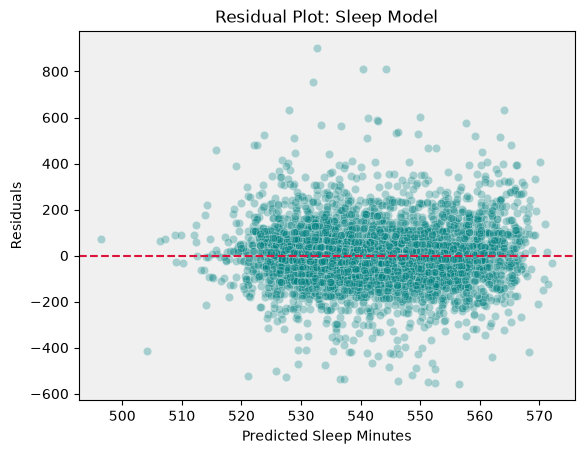

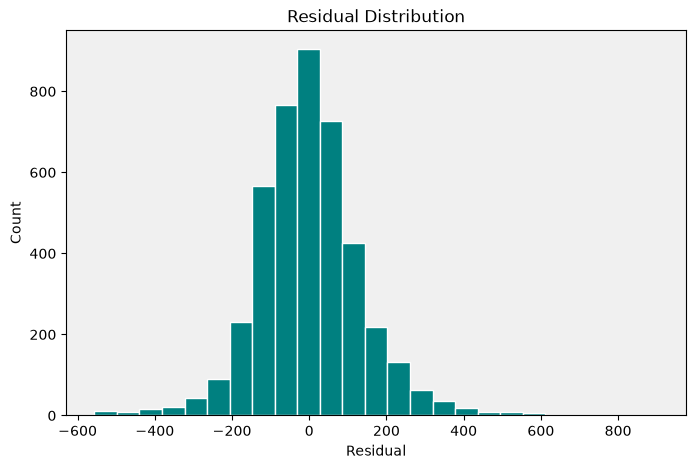

In [8]:
#Plot Residual Plot
residuals = sleep_model.resid
fitted_values = sleep_model.fittedvalues

sns.scatterplot(x = fitted_values, y = residuals, alpha = 0.3, color = "teal")
plt.axhline(y = 0, color = "crimson", linestyle = "--")
plt.xlabel("Predicted Sleep Minutes")
plt.ylabel("Residuals")
plt.title("Residual Plot: Sleep Model")
plt.gca().set_facecolor("#f0f0f0") 
plt.show()

#Plot Residual Distribution
plt.figure(figsize=(8,5))
plt.hist(sleep_model.resid, bins = 25, edgecolor = "white", color = "teal")
plt.xlabel("Residual")
plt.ylabel("Count")
plt.title("Residual Distribution")
plt.gca().set_facecolor("#f0f0f0") 
plt.show()

We can see that the residuals are generally scattered around zero, with no obvious curved pattern. This suggests that our model does not consistently overestimate or underestimate sleep duration and that the linearity assumption is reasonably satisfied. However, there are some points that are relatively far from zero, indicating that the model makes larger prediction errors for certain individuals. Overall, the graph suggests that the model's residuals are reasonably centered around zero, although there is still considerable unexplained variation in sleep duration.

**Sleep Data Conclusion.** Overall, our sleep data analysis did not provide strong evidence to support Hypothesis #2. We expected people who participated in more passive leisure activities, such as watching TV, to have poorer wellness outcomes than people who participated in active leisure activities. However, our regression results showed that none of the leisure activities had a statistically significant relationship with sleep duration. Age was the only significant predictor in our model. Additionally, our R-squared value of 0.008 indicates that the model explains very little of the variation in sleep duration. Therefore, we cannot conclude that passive leisure activities are associated with poorer sleep outcomes based on this analysis.

#### **Exercise and Sleep**

**Preparing the Mental Health Data.** We will use the cleaned BRFSS data, which includes 348,843 participants, to understand if exercise has an impact on sleep. 


bad_mental_health_days,0,1-13,14+
exercise,,,
Yes,60.16,27.52,12.31
No,57.28,21.57,21.15


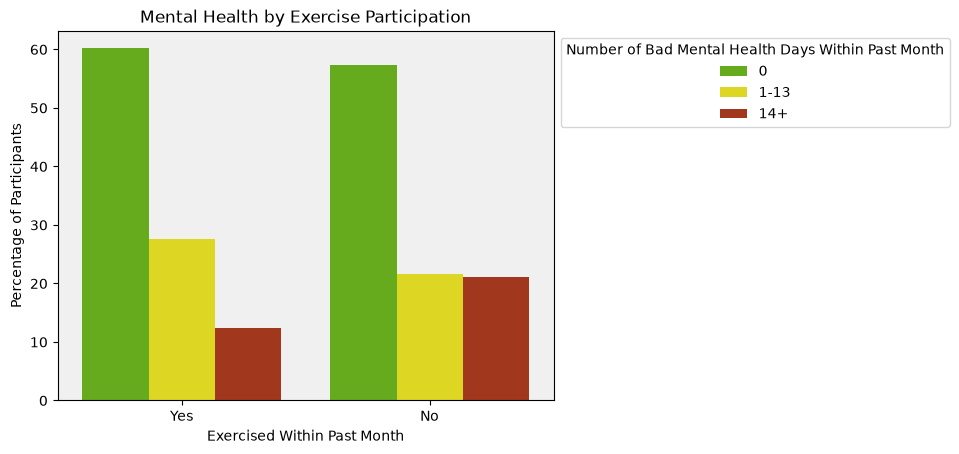

In [9]:
mental_health = pd.read_csv("data_cleaned/mental_health_people_cleaned.csv")

#Creating Cross-Tabulation
table = round(pd.crosstab(mental_health["exercise"], mental_health["bad_mental_health_days"], normalize = "index") * 100, 2)
table = table.rename(columns = {1: "0",
                              2: "1-13",
                              3: "14+"})
table = table.rename(index = {1: "Yes", 2: "No"})
display(table)
#Plotting Cross-Tabulation
plot_data = (table.rename_axis(index="exercise").reset_index().melt(id_vars = "exercise",
                                                                    var_name = "bad_mental_health_days",
                                                                    value_name = "percentage"))
day_colors = {"0" : "#67c107",
        "1-13" : "#fcf405",
        "14+" : "#b72a07"}
ax = sns.barplot(data = plot_data,
                 x = "exercise",
                 y = "percentage",
                 hue = "bad_mental_health_days",
                 palette = day_colors,
                 errorbar = None)

plt.title("Mental Health by Exercise Participation")
plt.xlabel("Exercised Within Past Month")
plt.ylabel("Percentage of Participants")
plt.legend(title = "Number of Bad Mental Health Days Within Past Month")
ax.set_facecolor("#f0f0f0")
plt.xticks(rotation = 0)
sns.move_legend(ax, "upper left", bbox_to_anchor = (1, 1));
plt.show()

Among participants who exercised within the past month, 60.16% reported no bad mental health days, compared with 57.28% of those who did not exercise. The percentage reporting 14 or more bad mental health days was higher among non-exercisers (21.15%) than exercisers (12.31%). However, 27.52% of exercisers reported 1–13 days, compared with 21.57% of non-exercisers. Overall, the largest difference is in the 14+ days category. These are associations in the data and do not show that exercise caused the difference.

Next, we will run a **Chi-Square Test** to determine whether exercise participation is independent from the frequency of bad mental health days. 

In [10]:
#Generate Observed Values
observed = pd.crosstab(mental_health['exercise'], mental_health['bad_mental_health_days'])
observed = observed.rename(columns = {1: "0",
                           2: "1-13",
                           3: "14+"})
observed = observed.rename(index = {1: "Yes", 2: "No"})
print("Observed Values: ")
display(observed.round(2))


row_totals = observed.sum(axis = 1)
column_totals = observed.sum(axis = 0)
grand_total = observed.to_numpy().sum()
#Calculate Expected Values
expected = np.outer(row_totals, column_totals) / grand_total

expected_table = pd.DataFrame(expected, index = observed.index, columns = observed.columns)
expected_table = expected_table.rename(columns = {1: "0",
                           2: "1-13",
                           3: "14+"})
expected_table = expected_table.rename(index = {1: "Yes", 2: "No"})

print("Expected Values:")
display(expected_table.round(2))

#Calculate Chi-Square Statistics
chi_square_contributions = ((observed - expected_table) ** 2) / expected_table
print("Chi-Square Test:")
display(chi_square_contributions.round(2))

chi2 = chi_square_contributions.to_numpy().sum()
print("Chi-square statistic:", round(chi2, 2))

dof = (observed.shape[0] - 1) * (observed.shape[1] - 1)
p = chi2_distribution.sf(chi2, dof)
print("Degrees of freedom:", dof)
print("P-value:", p)

n = observed.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * min(observed.shape[0] - 1, observed.shape[1] - 1)))
print("Cramér's V:", round(cramers_v, 2))

Observed Values: 


bad_mental_health_days,0,1-13,14+
exercise,,,
Yes,161605,73934,33078
No,45955,17304,16967


Expected Values:


bad_mental_health_days,0,1-13,14+
exercise,,,
Yes,159825.89,70255.32,38535.78
No,47734.11,20982.68,11509.22


Chi-Square Test:


bad_mental_health_days,0,1-13,14+
exercise,,,
Yes,19.80,192.62,772.98
No,66.31,644.94,2588.13


Chi-square statistic: 4284.79
Degrees of freedom: 2
P-value: 0.0
Cramér's V: 0.11


Our Chi-Square Test produced a chi-square statistic of 4,284.79 with 2 degrees of freedom and a p-value < 0.001.

Since the p-value was below the .05 significance level, the null hypothesis of independence was rejected. This indicates a statistically significant association between exercise participation and mental-health categories.

Cramér's V was calculated to measure the strength of this association. The resulting value of 0.11 suggests that the relationship is relatively weak, despite being statistically significant.

The observed frequencies also showed that participants who exercised reported fewer instances of frequent bad mental-health days than would be expected if the two variables were independent. However, these findings demonstrate an association rather than a causal relationship.

## **Conclusions**


## **Limitations**


The Cognitive Assessment dataset primarily includes younger participants, while HRS primarily includes older participants. Comparing overall averages could therefore reflect differences in the samples’ ages rather than differences in leisure activities or health outcomes. To address this limitation, we summarize each dataset within the same age groups. This allows us to examine age-related patterns separately within each dataset and compare patterns across corresponding groups. We also report participant counts and valid-response counts so that readers can identify groups with limited information.

This approach does **not** make the samples equally representative or eliminate age-related selection bias. Participants within the same age range may still differ across surveys, and broad groups can have different age distributions internally. 

### **Alternative (what we considered doing but didn't end up doing)**

An alternative would be to randomly select the same number of participants at each exact age from every survey. This could make the selected samples’ age distributions more similar, but it would require enough participants at every age in every dataset. Our datasets do not meet that requirement. Selecting equal numbers would also discard many valid observations from the larger datasets. Taking another random sample of 100 people from that reduced pool would further reduce precision and could disturb the age balance unless that final selection were also stratified by age. Neither step would make minutes, activity-frequency codes, and cognitive categories equivalent measurements.

For our descriptive analysis, retaining available valid observations within common age groups provides more information and makes differences in sample support visible. Equal-age sampling can be useful for a specifically defined comparison when sufficient overlapping data exist, but it is not necessary for our goal of comparing general age-related patterns.


## **Acknowledgements & Bibliography:**
Smith, Evan T., and Chandramallika Basak. “A Game-Factors Approach to Cognitive Benefits From Video-Game Training: A Meta-Analysis.” ProQuest, Aug. 2023, p. e0285925, <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; https://doi.org/10.1371/journal.pone.0285925. Accessed 10 Nov. 2026.<br>
Tompa, Rachel. “How Sleep Affects Mental Health (and Vice Versa): What the Science Says.” *Stanford Medicine*, Aug. 2025,<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; https://med.stanford.edu/news/insights/2025/08/sleep-mental-health-connection-what-science-says.html. Accessed 10 Nov. 2026. 